In [1]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

# Import modules
import matplotlib.pyplot as plt
import numpy as np

In [37]:
# 2 port source
E = lambda A1, A2, psi1, psi2: np.array(
    [A1 * np.exp(1j * psi1), A2 * np.exp(1j * psi2)],
    dtype=np.complex128,
)

# Beam splitter transfer matrix
DC = (1.0/np.sqrt(2)) * np.array([
    [1, -1j],
    [-1j, 1],
], dtype=np.complex128)

# Phase shift (Upper signal)
P = lambda theta: np.array(
    [[np.exp(1j * theta), 0],
     [0, 1]],
    dtype=np.complex128,
)

# MZI
MZI = lambda theta: DC @ P(theta) @ DC

# MZI + P
MZIP = lambda theta, phi: P(phi) @ MZI(theta)

def print_matrix(M):
    formatted = np.array2string(
        M,
        precision=2,
        suppress_small=True,
        max_line_width=100,
        separator="|",
    )
    print(formatted)

def embed_3x3(U2: np.ndarray, i: int, j: int) -> np.ndarray:
    # 3x3 identity matrix
    M3 = np.eye(3, dtype=np.complex128)
    M3[np.ix_([i, j], [i, j])] = U2
    return M3

# Logic cell
def logic_unit(p):
    t1, p1, t2, p2, t3, p3 = p
    
    M1 = embed_3x3(MZIP(t1, p1), 0, 1)
    M2 = embed_3x3(MZIP(t2 ,p2), 1, 2)
    M3 = embed_3x3(MZIP(t3 ,p3), 0, 1)

    return M3 @ M2 @ M1

NameError: name 'phase_top' is not defined

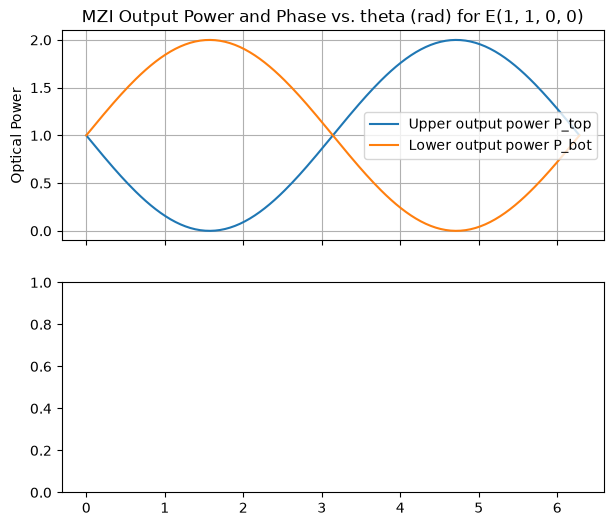

In [38]:
e_in = E(1,1,0,0)

thetas = np.linspace(0.0, 2.0 * np.pi, 200)

e_out = []
for t in thetas:
    mzi = MZI(t)
    e = mzi @ e_in
    e_out.append(e) 
    
e_out_arr = np.array(e_out)

p_top = np.abs(e_out_arr[:, 0])**2
p_bot = np.abs(e_out_arr[:, 1])**2


fig, (ax_pow, ax_ph) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

# Top subplot: Optical power
ax_pow.plot(thetas, p_top, label="Upper output power P_top")
ax_pow.plot(thetas, p_bot, label="Lower output power P_bot")
ax_pow.set_ylabel("Optical Power")
ax_pow.set_title("MZI Output Power and Phase vs. theta (rad) for E(1, 1, 0, 0)")
ax_pow.legend()
ax_pow.grid(True)

# Bottom subplot: Output phase
ax_ph.plot(thetas, phase_top, label="Upper output phase arg(E_top)")
ax_ph.plot(thetas, phase_bot, label="Lower output phase arg(E_bot)")
ax_ph.set_xlabel("Internal Phase theta (rad)")
ax_ph.set_ylabel("Phase (rad)")
ax_ph.set_xlim(0.0, 2.0 * np.pi)
ax_ph.set_xticks([0.0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2.0 * np.pi])
ax_ph.set_xticklabels(["0", "π/2", "π", "3π/2", "2π"])
ax_ph.set_yticks([-np.pi, -np.pi / 2, 0.0, np.pi / 2, np.pi])
ax_ph.set_yticklabels(["-π", "-π/2", "0", "π/2", "π"])
ax_ph.legend()
ax_ph.grid(True)

plt.tight_layout()
plt.show()

In [41]:
def logic_unit_sim(e_in, p):
    p = np.asarray(p, dtype=np.float64).copy()
    p[-1] = 0.0  # set only the last phase to 0.0

    U = logic_unit(p)
    e_out = U @ np.asarray(e_in, dtype=np.complex128)
    return e_out[0]

cases = [
# A | B | C | O
    (0, 0, 1, 0),
    (0, 1, 1, 0),
    (1, 0, 1, 0),
    (1, 1, 1, 1),
]

def loss(cases, p):
    total = 0.0
    for a, b, c, o in cases:
        e_in = np.array([a, b, c], dtype=np.complex128)
        e_out = logic_unit_sim(e_in, p)
        power_out = float(np.abs(e_out) ** 2)
        total += (power_out - o) ** 2
    return total / len(cases)

def grad_fd(cases, p, eps=1e-6):
    f0 = loss(cases, p)
    g = np.zeros_like(p, dtype=np.float64)
    for k in range(len(p)):
        p_plus = p.copy()
        p_plus[k] += eps
        g[k] = (loss(cases, p_plus) - f0) / eps
    return g

best_p = None
best_loss = np.inf
for seed in range(12):
    rng = np.random.default_rng(seed)
    p_cur = rng.uniform(-np.pi, np.pi, size=6)
    p_cur[-1] = 0.0
    lr = 0.25
    for _ in range(600):
        p_cur = p_cur - lr * grad_fd(cases, p_cur)
        p_cur[-1] = 0.0
    l_cur = loss(cases, p_cur)
    if l_cur < best_loss:
        best_loss = l_cur
        best_p = p_cur.copy()

print(f"Best MSE loss: {best_loss:.6f}")
print("Best phases [t1, p1, t2, p2, t3, 0.0]:", np.round(best_p, 2))
for a, b, c, o in cases:
    e_in = np.array([a, b, c], dtype=np.complex128)
    p_out = float(np.abs(logic_unit_sim(e_in, best_p)) ** 2)
    print(f"  A={a}, B={b}, C={c} | target O={o} | power_out={p_out:.4f}")

Best MSE loss: 0.009055
Best phases [t1, p1, t2, p2, t3, 0.0]: [ 4.62  2.36  0.31 -1.77 -2.43  0.  ]
  A=0, B=0, C=1 | target O=0 | power_out=0.1173
  A=0, B=1, C=1 | target O=0 | power_out=0.1032
  A=1, B=0, C=1 | target O=0 | power_out=0.1047
  A=1, B=1, C=1 | target O=1 | power_out=0.9708
